# 13 - Were the neural networks' COVID failures a fixable input problem?

Notebook 12 found the LSTM and hybrid were hurt in the crash by inputs far outside the training range (squared return up to 73 SD, clipped at +/-5 SD) and, for the hybrid, a network that lowered the GJR-GARCH forecast. Here we re-run the full five-fold evaluation of notebook 10 with three input designs:

* **A** - original inputs (z-scored, clipped at +/-5 SD): baseline.
* **B** - log inputs: log of each volatility feature, return divided by sqrt(GJR-GARCH forecast), z-scored on training data only, wide +/-10 safety clip (we report how often it binds).
* **C** - B plus the log of the range-based proxy and its 5- and 22-day averages (HAR-style).

All networks are still trained with QLIKE on *squared returns*; only the inputs change. Same fold boundaries, seeds (5) and architecture as notebook 10, now with deterministic TensorFlow ops.

In [1]:
import os, sys, warnings, time
sys.path.append("..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import yfinance as yf
import tensorflow as tf
tf.config.experimental.enable_op_determinism()
from tensorflow import keras  # type: ignore
from arch import arch_model
from arch.bootstrap import MCS
from pathlib import Path

SMOKE = os.environ.get("NB13_SMOKE") == "1"          # quick wiring test only (1 fold, 1 seed, 2 epochs)
START = "2010-01-01"
END = "2026-11-06"                                     # exclusive: last day used is 2026-11-05. Pinned so fold boundaries (fractions of n) never shift between runs
N_SEEDS = 1 if SMOKE else 5
EPOCHS = 2 if SMOKE else 200
LOOK = 22
FOLD_STARTS = [0.6] if SMOKE else [0.5, 0.6, 0.7, 0.8, 0.9]
FOLD_LEN = 0.1
REFIT_EVERY = 20
EPS = 1e-4                                            # epsilon inside the logs
OUT_FILE = Path("../data/nb13_smoke.csv" if SMOKE else "../data/nb13_fold_forecasts.csv")
OUT_FILE.parent.mkdir(exist_ok=True)
CRASH_START, CRASH_END = pd.Timestamp("2020-02-20"), pd.Timestamp("2020-04-30")

In [2]:
_cache = {}
def load_data(ticker):
    if ticker not in _cache:
        px = yf.download(ticker, start=START, end=END, auto_adjust=True, progress=False)
        if isinstance(px.columns, pd.MultiIndex):
            px.columns = px.columns.get_level_values(0)
        px = px[["Open", "High", "Low", "Close"]].dropna()
        r = (100 * np.log(px["Close"] / px["Close"].shift(1))).dropna()
        r.name = "log_return"
        _cache[ticker] = (r, px)
    return _cache[ticker]

def range_proxy(r, px):
    lnHL = np.log(px["High"] / px["Low"])
    lnCO = np.log(px["Close"] / px["Open"])
    lnON = np.log(px["Open"] / px["Close"].shift(1))
    gk = 1e4 * (0.5 * lnHL ** 2 - (2 * np.log(2) - 1) * lnCO ** 2)
    gk_on = (gk + 1e4 * lnON ** 2).loc[r.index]
    sq_ret = r ** 2
    roll_scale = (sq_ret.rolling(252, min_periods=126).sum()
                  / gk_on.rolling(252, min_periods=126).sum()).shift(1).bfill()
    return (roll_scale * gk_on).clip(lower=1e-6)

SPECS = {
    "GARCH(1,1)": dict(vol="GARCH", p=1, q=1),
    "EGARCH":     dict(vol="EGARCH", p=1, o=1, q=1),
    "GJR-GARCH":  dict(vol="GARCH", p=1, o=1, q=1),
}

def garch_forecasts(r, split, end):
    gf_all, test = {}, {}
    for name, spec in SPECS.items():
        res = arch_model(r, mean="Constant", dist="t", **spec).fit(last_obs=r.index[split - 1], disp="off")
        gf = res.forecast(horizon=1, start=r.index[0], reindex=False).variance["h.1"]
        gf_all[name] = gf
        test[name] = gf.shift(1).loc[r.index[split:end]]
    test["Rolling 21d var"] = r.rolling(21).var().shift(1).loc[r.index[split:end]]
    return gf_all, pd.DataFrame(test)

def har_design(x):
    return pd.DataFrame({"daily": x, "weekly": x.rolling(5).mean(), "monthly": x.rolling(22).mean()})

def rolling_har(series, split, end, log=False):
    x = np.log(series) if log else series
    X = sm.add_constant(har_design(x))
    y_next = x.shift(-1)
    preds = []
    for s in range(split, end, REFIT_EVERY):
        e = min(s + REFIT_EVERY, end)
        Xt, yt = X.iloc[: s - 1], y_next.iloc[: s - 1]
        ok = Xt.notna().all(axis=1) & yt.notna()
        res = sm.OLS(yt[ok], Xt[ok]).fit()
        p = res.predict(X.iloc[s - 1: e - 1])
        if log:
            p = np.exp(p + 0.5 * res.mse_resid)
        preds.append(pd.Series(p.values, index=series.index[s:e]))
    return pd.concat(preds)

In [3]:
def qlike_loss(y_true, y_pred):
    y_, base = y_true[:, 0:1], y_true[:, 1:2]
    out = tf.clip_by_value(y_pred, -4.0, 4.0)
    f = base * tf.exp(out)
    return tf.reduce_mean(tf.math.log(f) + y_ / f)

def build_model(n_feat, lr=3e-4):
    m = keras.Sequential([
        keras.layers.Input(shape=(LOOK, n_feat)),
        keras.layers.LSTM(16),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(1, kernel_initializer="zeros", bias_initializer="zeros"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(lr), loss=qlike_loss)
    return m

def train_ensemble(s, n_seeds):
    """(ensemble-mean forecast, per-seed clipped log-multipliers [seeds x days])"""
    preds, outs = [], []
    for seed in range(n_seeds):
        keras.utils.set_random_seed(seed)                # python + numpy + tensorflow seeds
        m = build_model(s["X_tr"].shape[2])
        early = keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True)
        m.fit(s["X_tr"], s["Y_tr"], validation_data=(s["X_val"], s["Y_val"]),
              epochs=EPOCHS, batch_size=64, callbacks=[early], verbose=0)
        out = np.clip(m.predict(s["X_te"], verbose=0).ravel(), -4, 4)
        outs.append(out)
        preds.append(s["Y_te"][:, 1] * np.exp(out))
    return np.array(preds).mean(axis=0), np.array(outs)

def make_features(r, proxy_rb, gjr_gf, variant):
    """Row t uses information up to the close of day t only. Returns (features, LSTM cols, hybrid cols, clip)."""
    abs5 = r.abs().rolling(5).mean()
    rv21 = r.rolling(21).std() * np.sqrt(252)
    if variant == "A":
        f = pd.DataFrame({"ret": r, "sq_ret": r ** 2, "abs_mean_5d": abs5, "rv_21d": rv21})
        lstm_cols = list(f.columns)
        f["log_garch_var"] = np.log(gjr_gf)
        return f.dropna(), lstm_cols, list(f.columns), 5.0
    f = pd.DataFrame({
        "ret_std": r / np.sqrt(gjr_gf.shift(1)),          # return / sqrt(forecast made the day before)
        "log_sq_ret": np.log(r ** 2 + EPS),
        "log_abs_5d": np.log(abs5 + EPS),
        "log_rv_21d": np.log(rv21 + EPS),
    })
    if variant == "C":
        f["log_rb"] = np.log(proxy_rb)
        f["log_rb_5d"] = np.log(proxy_rb.rolling(5).mean())
        f["log_rb_22d"] = np.log(proxy_rb.rolling(22).mean())
    lstm_cols = list(f.columns)
    f["log_garch_var"] = np.log(gjr_gf)
    return f.dropna(), lstm_cols, list(f.columns), 10.0

def nn_forecasts(r, proxy_rb, gjr_gf, split, end, variant):
    feat, lstm_cols, hyb_cols, clip = make_features(r, proxy_rb, gjr_gf, variant)
    split_date = r.index[split]
    end_date = r.index[end] if end < len(r) else r.index[-1] + pd.Timedelta(days=1)

    tr = feat.index < split_date                          # scaling uses training data only
    mu, sd = feat[tr].mean(), feat[tr].std()
    z = (feat - mu) / sd
    z_clipped = z.clip(-clip, clip)
    idx = z.index
    rsq = (r ** 2).loc[idx].values
    gv = gjr_gf.loc[idx].values
    col_pos = {c: i for i, c in enumerate(z.columns)}
    vals = z_clipped.values

    X, y, g, dates = [], [], [], []
    for t in range(LOOK, len(idx)):
        X.append(vals[t - LOOK:t]); y.append(rsq[t]); g.append(gv[t - 1]); dates.append(idx[t])
    X, y, g, dates = np.array(X), np.array(y), np.array(g), pd.DatetimeIndex(dates)

    train_mask = dates < split_date
    test_mask = (dates >= split_date) & (dates < end_date)
    const_var = (r ** 2)[r.index < split_date].mean()

    def make_sets(cols, base):
        Xc = X[:, :, [col_pos[c] for c in cols]]
        Y = np.column_stack([y, base])
        Xa, Ya = Xc[train_mask], Y[train_mask]
        v = int(len(Xa) * 0.9)
        return dict(X_tr=Xa[:v], Y_tr=Ya[:v], X_val=Xa[v:], Y_val=Ya[v:], X_te=Xc[test_mask], Y_te=Y[test_mask])

    out = pd.DataFrame(index=dates[test_mask])
    out[f"Hybrid-{variant}"], hyb_raw = train_ensemble(make_sets(hyb_cols, g), N_SEEDS)
    out[f"LSTM-{variant}"], _ = train_ensemble(make_sets(lstm_cols, np.full(len(y), const_var)), N_SEEDS)

    # how often the input clip binds, over the feature dates of the test block (all model inputs)
    zt = z.loc[(z.index >= split_date) & (z.index < end_date), hyb_cols]
    zc = z.loc[CRASH_START:CRASH_END, hyb_cols]
    clip_stats = {"clip": clip, "share of test feature-values clipped": float((zt.abs() > clip).values.mean()),
                  "share clipped in crash window": float((zc.abs() > clip).values.mean()) if len(zc) else np.nan,
                  "most-clipped feature": (zt.abs() > clip).mean().idxmax()}
    return out, pd.DataFrame(hyb_raw.T, index=dates[test_mask]), clip_stats

In [4]:
VARIANTS = ["A", "B", "C"]
r, px = load_data("^GSPC")
proxy_rb = range_proxy(r, px)
PROXIES = {"Squared returns": r ** 2, "Range-based": proxy_rb}
n = len(r)

import json
CKPT = "nb13_smoke_fold" if SMOKE else "nb13_fold"
def ckpt(k, suffix): return OUT_FILE.parent / f"{CKPT}{k}{suffix}"

folds, hyb_raw, clip_log = [], {}, []
for k, frac in enumerate(FOLD_STARTS, start=1):
    t0 = time.time()
    split = int(n * frac)
    end = min(int(n * (frac + FOLD_LEN)), n)             # same expression as notebook 10
    if frac == 0.6:
        assert r.index[split] == pd.Timestamp("2020-02-10"), r.index[split]
    # Resume: the forecasts file is written LAST, so its existence means the fold is complete.
    if ckpt(k, ".csv").exists():
        fc = pd.read_csv(ckpt(k, ".csv"), index_col=0, parse_dates=True)
        assert fc.index[0] == r.index[split] and fc.index[-1] == r.index[end - 1], f"checkpoint {k} does not match current fold boundaries"
        for v in VARIANTS:
            hyb_raw[(frac, v)] = pd.read_csv(ckpt(k, f"_hybraw_{v}.csv"), index_col=0, parse_dates=True)
        clip_log += json.load(open(ckpt(k, "_clip.json")))
        folds.append(fc)
        print(f"fold {frac:.1f}: loaded checkpoint {ckpt(k, '.csv').name} ({len(fc)} days)", flush=True)
        continue
    gf_all, fc = garch_forecasts(r, split, end)
    floor = 0.01 * proxy_rb.iloc[:split].mean()
    fc["HAR"] = rolling_har(proxy_rb, split, end).clip(lower=floor)
    fc["log-HAR"] = rolling_har(proxy_rb, split, end, log=True)
    fold_clip = []
    for v in VARIANTS:
        nn, raw, cs = nn_forecasts(r, proxy_rb, gf_all["GJR-GARCH"], split, end, v)
        fc = fc.join(nn, how="inner")
        hyb_raw[(frac, v)] = raw
        fold_clip.append({"fold": frac, "variant": v, **cs})
        raw.to_csv(ckpt(k, f"_hybraw_{v}.csv"))
    clip_log += fold_clip
    json.dump(fold_clip, open(ckpt(k, "_clip.json"), "w"))
    fc = fc.dropna().clip(lower=1e-8)
    fc.to_csv(ckpt(k, ".csv"))                           # written last = checkpoint complete
    folds.append(fc)
    print(f"fold {frac:.1f}: test {fc.index[0].date()} to {fc.index[-1].date()} ({len(fc)} days), {time.time() - t0:.0f}s [checkpoint saved]", flush=True)

MODELS = list(folds[0].columns)
saved = pd.concat([f.assign(fold=i + 1) for i, f in enumerate(folds)])
saved["sq_ret_proxy"] = (r ** 2).loc[saved.index]
saved["range_proxy"] = proxy_rb.loc[saved.index]
saved.to_csv(OUT_FILE)
print("saved", OUT_FILE.resolve(), saved.shape)

fold 0.5: loaded checkpoint nb13_fold1.csv (423 days)


fold 0.6: loaded checkpoint nb13_fold2.csv (424 days)


fold 0.7: loaded checkpoint nb13_fold3.csv (423 days)


fold 0.8: test 2023-06-22 to 2025-02-28 (424 days), 725s [checkpoint saved]


fold 0.9: test 2025-03-03 to 2026-11-05 (424 days), 908s [checkpoint saved]


saved C:\Users\iminl\Documents\Hackathons\DS+X\volatility-forecasting\data\nb13_fold_forecasts.csv (2118, 15)


## 0. Does the +/-10 safety clip bind (B, C), and how much does the +/-5 clip bind (A)?

In [5]:
display(pd.DataFrame(clip_log).set_index(["fold", "variant"]).round(4))

clip  share of test feature-values clipped  \
fold variant                                               
0.5  A         5.0                                0.0009   
     B        10.0                                0.0000   
     C        10.0                                0.0000   
0.6  A         5.0                                0.0448   
     B        10.0                                0.0000   
     C        10.0                                0.0000   
0.7  A         5.0                                0.0005   
     B        10.0                                0.0000   
     C        10.0                                0.0000   
0.8  A         5.0                                0.0000   
     B        10.0                                0.0000   
     C        10.0                                0.0000   
0.9  A         5.0                                0.0033   
     B        10.0                                0.0000   
     C        10.0                                0.0000   

              share clipped in crash window most-clipped feature  
fold variant                                                      
0.5  A                                0.352                  ret  
     B                                0.000              ret_std  
     C                                0.000              ret_std  
0.6  A                                0.364               rv_21d  
     B                                0.000              ret_std  
     C                                0.000              ret_std  
0.7  A                                0.228               sq_ret  
     B                                0.000              ret_std  
     C                                0.000              ret_std  
0.8  A                                0.224                  ret  
     B                                0.000              ret_std  
     C                                0.000              ret_std  
0.9  A                                0.240               sq_ret  
     B                                0.000              ret_std  
     C                                0.000              ret_std

## 1. Per-fold QLIKE under each proxy (lower is better)

In [6]:
def fold_table(proxy):
    rows = {}
    for fc in folds:
        p = proxy.loc[fc.index]
        rows[f"{fc.index[0].date()} to {fc.index[-1].date()}"] = fc.apply(lambda f: (np.log(f) + p / f).mean())
    return pd.DataFrame(rows).T

tables = {pn: fold_table(p) for pn, p in PROXIES.items()}
for pn, tab in tables.items():
    print(f"QLIKE by test block - {pn} proxy")
    display(tab.round(4))
    rel = tab.sub(tab["GJR-GARCH"], axis=0)
    print("Folds beating GJR-GARCH: " + ", ".join(f"{m} {(rel[m] < 0).sum()}/{len(rel)}" for m in MODELS if m != "GJR-GARCH") + "\n")

QLIKE by test block - Squared returns proxy

,"GARCH(1,1)",EGARCH,GJR-GARCH,Rolling 21d var,HAR,log-HAR,Hybrid-A,LSTM-A,Hybrid-B,LSTM-B,Hybrid-C,LSTM-C
2018-06-05 to 2020-02-07,0.4879,0.3861,0.4180,0.7048,0.4298,0.3912,0.4055,0.3947,0.4080,0.3832,0.3627,0.3437
2020-02-10 to 2021-10-13,1.2716,1.6696,1.4351,1.4506,1.2288,1.2261,1.4903,1.7108,1.5070,1.6443,1.3165,1.5084
2021-10-14 to 2023-06-21,1.4771,1.4292,1.4639,1.4945,1.4740,1.4173,1.4486,1.4080,1.4531,1.3992,1.4155,1.3903
2023-06-22 to 2025-02-28,0.5253,0.4940,0.4891,0.6340,0.5072,0.5025,0.4749,0.4364,0.4818,0.4462,0.5135,0.4717
2025-03-03 to 2026-11-05,0.8126,0.7422,0.7351,0.9554,0.6905,0.6923,0.7261,0.7246,0.7251,0.7411,0.7335,0.7481


Folds beating GJR-GARCH: GARCH(1,1) 1/5, EGARCH 2/5, Rolling 21d var 0/5, HAR 2/5, log-HAR 4/5, Hybrid-A 4/5, LSTM-A 4/5, Hybrid-B 4/5, LSTM-B 3/5, Hybrid-C 4/5, LSTM-C 3/5

QLIKE by test block - Range-based proxy


,"GARCH(1,1)",EGARCH,GJR-GARCH,Rolling 21d var,HAR,log-HAR,Hybrid-A,LSTM-A,Hybrid-B,LSTM-B,Hybrid-C,LSTM-C
2018-06-05 to 2020-02-07,0.4914,0.4443,0.4518,0.6956,0.4734,0.4583,0.4337,0.4653,0.4345,0.4514,0.4459,0.4663
2020-02-10 to 2021-10-13,1.3711,1.6478,1.4930,1.5147,1.3115,1.3221,1.5727,1.8821,1.5526,1.7922,1.4030,1.6451
2021-10-14 to 2023-06-21,1.3912,1.3726,1.4020,1.4936,1.4244,1.3954,1.3786,1.3717,1.3851,1.3661,1.3755,1.3578
2023-06-22 to 2025-02-28,0.4898,0.4667,0.4619,0.5716,0.4758,0.4668,0.4527,0.4456,0.4572,0.4457,0.4737,0.4491
2025-03-03 to 2026-11-05,0.7324,0.6800,0.6689,0.8326,0.6880,0.6896,0.6570,0.6620,0.6561,0.6746,0.6676,0.7105


Folds beating GJR-GARCH: GARCH(1,1) 2/5, EGARCH 2/5, Rolling 21d var 0/5, HAR 1/5, log-HAR 2/5, Hybrid-A 4/5, LSTM-A 3/5, Hybrid-B 4/5, LSTM-B 3/5, Hybrid-C 4/5, LSTM-C 2/5



## 2-3. Pooled Diebold-Mariano tests and 90% Model Confidence Set

In [7]:
def dm_test(L_a, L_b, lags=5):
    d = (L_a - L_b).values
    res = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return res.tvalues[0], res.pvalues[0]

pooled = pd.concat(folds)
print(f"Pooled over {len(pooled)} test days")
for pn, p in PROXIES.items():
    proxy = p.loc[pooled.index]
    L = pooled.apply(lambda f: np.log(f) + proxy / f)
    rows = {}
    for m in MODELS:
        row = {"QLIKE": L[m].mean()}
        for base in ["GJR-GARCH", "log-HAR"]:
            if m != base:
                row[f"DM vs {base}"], row[f"p vs {base}"] = dm_test(L[m], L[base])
        rows[m] = row
    print(f"\n===== {pn} proxy: pooled QLIKE and Diebold-Mariano (negative DM = lower loss than the benchmark) =====")
    display(pd.DataFrame(rows).T.sort_values("QLIKE").round(3))
    mcs = MCS(L, size=0.10, reps=1000, seed=42)
    mcs.compute()
    print("90% Model Confidence Set:", list(mcs.included))

Pooled over 2118 test days

===== Squared returns proxy: pooled QLIKE and Diebold-Mariano (negative DM = lower loss than the benchmark) =====


,QLIKE,DM vs GJR-GARCH,p vs GJR-GARCH,DM vs log-HAR,p vs log-HAR
log-HAR,0.846,-1.635,0.102,NaN,NaN
HAR,0.866,-1.117,0.264,2.442,0.015
Hybrid-C,0.868,-2.477,0.013,0.785,0.432
LSTM-C,0.892,-0.411,0.681,1.104,0.270
GJR-GARCH,0.908,NaN,NaN,1.635,0.102
Hybrid-A,0.909,0.057,0.955,1.394,0.163
"GARCH(1,1)",0.915,0.199,0.842,4.439,0.000
Hybrid-B,0.915,0.502,0.615,1.476,0.140
LSTM-B,0.923,0.439,0.660,1.616,0.106
LSTM-A,0.935,0.614,0.539,1.677,0.093


90% Model Confidence Set: ['EGARCH', 'GJR-GARCH', 'HAR', 'Hybrid-A', 'Hybrid-B', 'Hybrid-C', 'LSTM-A', 'LSTM-B', 'LSTM-C', 'log-HAR']

===== Range-based proxy: pooled QLIKE and Diebold-Mariano (negative DM = lower loss than the benchmark) =====


,QLIKE,DM vs GJR-GARCH,p vs GJR-GARCH,DM vs log-HAR,p vs log-HAR
log-HAR,0.866,-1.509,0.131,NaN,NaN
Hybrid-C,0.873,-2.101,0.036,0.474,0.635
HAR,0.875,-1.045,0.296,1.545,0.122
"GARCH(1,1)",0.895,-0.022,0.983,2.892,0.004
GJR-GARCH,0.896,NaN,NaN,1.509,0.131
Hybrid-B,0.897,0.202,0.840,1.295,0.195
Hybrid-A,0.899,0.325,0.745,1.375,0.169
EGARCH,0.922,1.199,0.230,1.485,0.138
LSTM-C,0.926,0.972,0.331,1.835,0.067
LSTM-B,0.946,1.616,0.106,2.231,0.026


90% Model Confidence Set: ['EGARCH', 'GARCH(1,1)', 'GJR-GARCH', 'HAR', 'Hybrid-A', 'Hybrid-B', 'Hybrid-C', 'LSTM-A', 'LSTM-B', 'LSTM-C', 'log-HAR']


## 4. COVID fold (fold 2)
Phases as in notebook 12: pre-crash (to Feb 19), crash (Feb 20 - Apr 30), recovery (May 1 on). Contributions = sum over the phase of (model loss - GJR-GARCH loss) divided by the fold length, so they add up to the fold-average QLIKE gap.

In [8]:
fc2 = folds[1] if not SMOKE else folds[0]
frac2 = 0.6
phase = pd.Series("recovery", index=fc2.index)
phase[fc2.index < CRASH_START] = "pre-crash"
phase[(fc2.index >= CRASH_START) & (fc2.index <= CRASH_END)] = "crash"
PH = ["pre-crash", "crash", "recovery"]
show = ["GJR-GARCH", "HAR", "log-HAR"] + [f"{a}-{v}" for a in ["LSTM", "Hybrid"] for v in VARIANTS]
cw = fc2.loc[CRASH_START:CRASH_END]

peaks = pd.DataFrame({"peak forecast": cw[show].max(), "peak date": cw[show].idxmax().dt.date})
display(peaks.round(2))
print("Proxy peaks in the crash window:", {pn: round(p.loc[CRASH_START:CRASH_END].max(), 1) for pn, p in PROXIES.items()})

for pn, p in PROXIES.items():
    L = fc2.apply(lambda f: np.log(f) + p.loc[fc2.index] / f)
    d = L.sub(L["GJR-GARCH"], axis=0).groupby(phase).sum().T[PH] / len(L)
    d["total gap"] = d.sum(axis=1)
    print(f"Contribution to fold-average QLIKE gap vs GJR-GARCH - {pn} (negative = better than GJR-GARCH)")
    display(d.loc[[m for m in show if m != "GJR-GARCH"]].round(4))

rows = {}
for v in VARIANTS:
    lm = np.log(fc2[f"Hybrid-{v}"] / fc2["GJR-GARCH"])
    raw = hyb_raw[(frac2, v)]
    rows[f"Hybrid-{v}"] = {"mean log-mult (crash)": lm[phase == "crash"].mean(),
                           "x multiplier": np.exp(lm[phase == "crash"].mean()),
                           "share of crash days raised": (lm[phase == "crash"] > 0).mean(),
                           "mean log-mult (recovery)": lm[phase == "recovery"].mean(),
                           "share of seed-days at +/-4 clip": float((raw.abs() >= 4 - 1e-6).values.mean())}
display(pd.DataFrame(rows).T.round(3))

,peak forecast,peak date
GJR-GARCH,89.95,2020-03-17
HAR,60.18,2020-03-17
log-HAR,37.28,2020-03-19
LSTM-A,5.17,2020-03-24
LSTM-B,5.45,2020-03-20
LSTM-C,5.55,2020-03-20
Hybrid-A,40.80,2020-03-17
Hybrid-B,45.28,2020-03-17
Hybrid-C,54.04,2020-03-17


Proxy peaks in the crash window: {'Squared returns': np.float64(163.0), 'Range-based': np.float64(142.9)}
Contribution to fold-average QLIKE gap vs GJR-GARCH - Squared returns (negative = better than GJR-GARCH)


,pre-crash,crash,recovery,total gap
HAR,0.0006,0.0392,-0.2461,-0.2063
log-HAR,-0.0006,0.0572,-0.2656,-0.2090
LSTM-A,-0.0041,0.3205,-0.0406,0.2757
LSTM-B,-0.0047,0.2594,-0.0456,0.2092
LSTM-C,-0.0045,0.2299,-0.1521,0.0733
Hybrid-A,-0.0045,0.0551,0.0046,0.0552
Hybrid-B,-0.0034,0.0376,0.0377,0.0719
Hybrid-C,-0.0035,0.0218,-0.1369,-0.1186


Contribution to fold-average QLIKE gap vs GJR-GARCH - Range-based (negative = better than GJR-GARCH)


,pre-crash,crash,recovery,total gap
HAR,0.0003,0.0226,-0.2044,-0.1815
log-HAR,-0.0000,0.0377,-0.2085,-0.1709
LSTM-A,-0.0018,0.3491,0.0418,0.3891
LSTM-B,-0.0019,0.2557,0.0454,0.2992
LSTM-C,-0.0017,0.2236,-0.0699,0.1521
Hybrid-A,-0.0019,0.0581,0.0236,0.0797
Hybrid-B,-0.0016,0.0257,0.0355,0.0596
Hybrid-C,-0.0014,0.0153,-0.1039,-0.0900


,mean log-mult (crash),x multiplier,share of crash days raised,mean log-mult (recovery),share of seed-days at +/-4 clip
Hybrid-A,-0.634,0.531,0.06,-0.114,0.0
Hybrid-B,-0.392,0.676,0.06,-0.111,0.0
Hybrid-C,-0.210,0.811,0.30,-0.082,0.0


### Forecast paths, Feb - Jun 2020 (log scale)

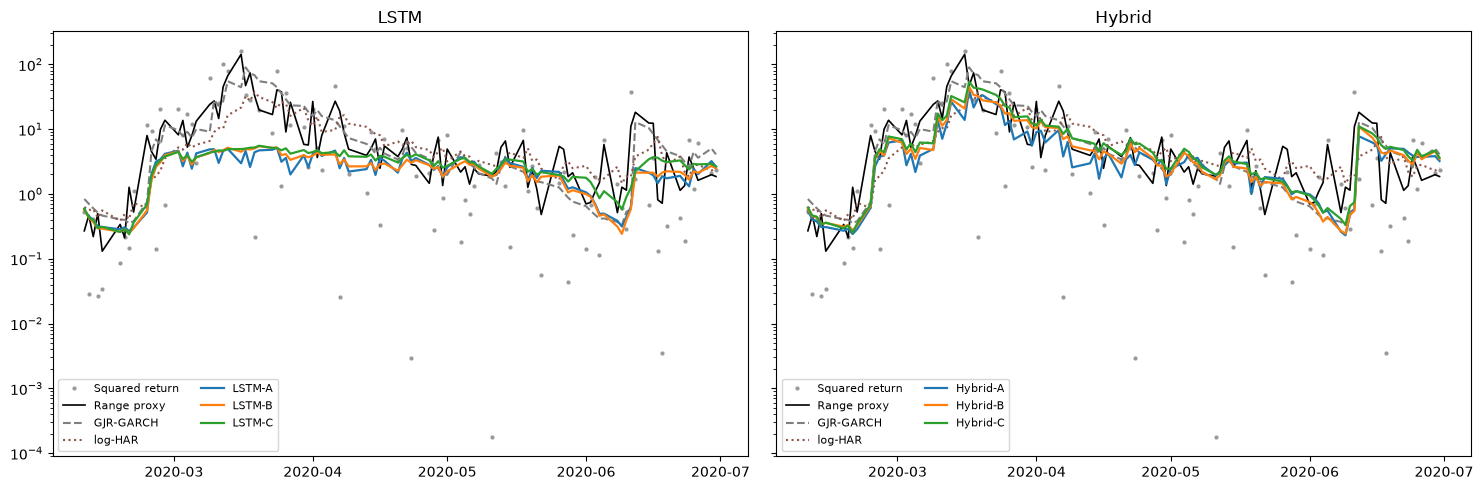

In [9]:
w = slice("2020-02-10", "2020-06-30")
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, a in zip(axes, ["LSTM", "Hybrid"]):
    ax.plot(r.loc[w].index, (r ** 2).loc[w], ".", color="0.6", ms=4, label="Squared return")
    ax.plot(proxy_rb.loc[w].index, proxy_rb.loc[w], "k-", lw=1.2, label="Range proxy")
    ax.plot(fc2.loc[w].index, fc2.loc[w, "GJR-GARCH"], "--", color="C7", label="GJR-GARCH")
    ax.plot(fc2.loc[w].index, fc2.loc[w, "log-HAR"], ":", color="C5", label="log-HAR")
    for v in VARIANTS:
        ax.plot(fc2.loc[w].index, fc2.loc[w, f"{a}-{v}"], lw=1.6, label=f"{a}-{v}")
    ax.set_yscale("log"); ax.set_title(a); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

## Summary: were the COVID failures a fixable input problem?

*Data pinned to end 2026-11-05 (one day longer than notebooks 10 and 12, so fold dates differ by a day). Networks are deterministic here (op determinism on, 5 seeds). In section 0, only the fold-2 row of the "crash window" column is meaningful, because the other folds' test blocks do not contain that window.*

1. **Log inputs alone (B) did not fix it.** B removes the clipping problem (variant A had 4.5% of fold-2 input values clipped at +/-5 SD, 36% inside the crash window; B and C never touched the +/-10 clip). But the LSTM still peaked at 5.5 (A: 5.2) against proxy peaks of 143-163, and its crash-phase gap vs GJR-GARCH only fell from +0.32 to +0.26 (squared returns; range proxy +0.35 to +0.26). The Hybrid-B total fold-2 gap (+0.072 / +0.060) is no better than Hybrid-A (+0.055 / +0.080), and it still lowered the GARCH forecast in the crash (log-multiplier -0.39 vs -0.63 for A; raised on 6% of crash days).
2. **Adding range information (C) is what helped, mainly for the hybrid.** Hybrid-C is the only network variant that beats GJR-GARCH in the COVID fold (total gap -0.119 squared returns, -0.090 range proxy). Its crash-phase gap shrank to +0.022 / +0.015, its peak forecast rose to 54 (A: 41), it raised the forecast on 30% of crash days (mean log-multiplier -0.21), and it gained -0.14 / -0.10 in the recovery. LSTM-C improved on A and B in the fold (gap +0.073 / +0.152) but remains worse than GJR-GARCH.
3. **Pooled over all five folds (2,118 days):** Hybrid-C is significantly better than GJR-GARCH (DM -2.48, p = 0.013 on squared returns; -2.10, p = 0.036 on the range proxy). Hybrid-A, Hybrid-B and every LSTM variant are not. Hybrid-C is statistically indistinguishable from log-HAR (p = 0.43 / 0.64), and log-HAR still has the lowest pooled QLIKE (0.846 / 0.866 vs 0.868 / 0.873). The 90% Model Confidence Set is not selective: it keeps 10 of 12 models on squared returns (dropping GARCH(1,1) and Rolling 21d var) and 11 of 12 on the range proxy (dropping only Rolling 21d var), including all six network variants.
4. **Reading.** Part of the failure was a fixable input problem, but only when the inputs carry range-based volatility information; rescaling alone did not help. That gain essentially matches what a plain log-HAR on the same range proxy already achieves, so the networks do not add accuracy beyond it. The LSTM's crash failure (peak about 5.5 in every variant) is not explained by input scaling, and I have not tested other causes (for example its constant base variance).
5. **Caveats.** One crash episode and five folds; the networks are trained on squared returns in every variant; Hybrid-C's fold-1 result is worse than Hybrid-A on the range proxy (0.446 vs 0.434) even though it is better on squared returns, so the improvement is not uniform across folds. Per-fold forecasts for all models are saved in `data/nb13_fold_forecasts.csv` (and `nb13_fold1-5.csv`).
